# Jakarta air quality: visible preprocessing and export

Run all cells in order using the project's `.venv` Python environment. Each processing stage preserves a copy of its data and displays row counts, missing values and examples of changed records. Downloads use the configured API keys.

The final cells save a timestamped run under `outputs/air-quality-review/`: an Excel workbook, one CSV per stage, full raw API responses and nine diagnostic PNG graphs. The Excel export is implemented in Python inside this notebook.

**Outlier flags are descriptive:** extreme valid pollution readings are retained. The existing physical-range and channel-agreement rules remain the cleaning criteria.


## Dataset sources, reproducibility and assignment scope

**Question:** How do cleaning, hourly alignment and weather integration change a January 2024 Jakarta PM2.5 dataset, and how many standardized components summarize its variation?

- **OpenAQ:** [dataset/API documentation](https://docs.openaq.org/), [location query](https://api.openaq.org/v3/locations?bbox=106.689,-6.370,106.978,-6.079&parameters_id=2&limit=1000), [licensing metadata](https://docs.openaq.org/resources/licenses). Provider names and licenses are retained below. OpenAQ includes several sensor technologies; it is not uniformly a reference-monitor network.
- **Meteostat:** [hourly weather](https://dev.meteostat.net/python/api/meteostat.hourly), [data license](https://dev.meteostat.net/license). Used for temperature, humidity, rainfall, wind speed and pressure.
- **PurpleAir (supplementary comparison):** [API](https://api.purpleair.com/), [access documentation](https://community.purpleair.com/t/about-the-purpleair-api/7145). Public-sensor history requires a key and may require API credits. Public visibility alone does not establish an open redistribution license.

The **primary open-data PCA cohort** uses only OpenAQ sensors whose returned metadata explicitly names US Public Domain, CC0 1.0 or CC BY 4.0, plus Meteostat weather. Other OpenAQ records and PurpleAir remain labeled supplementary observations in the integration audit. This avoids assuming that all accessible data have the same license.

The geographical bounds, fixed month, source combination, sensor selection and before/after audit make the analysis specific. **Uniqueness across classmates must be confirmed with the instructor/class dataset register.** No plagiarism or uniqueness guarantee is possible from these files alone.

Default execution replays the saved, unchanged source responses in `data/air_quality_snapshot` so results do not depend on API availability or credentials. Set `USE_SAVED_DATA = False` and environment variables `OPENAQ_API_KEY` and `PURPLEAIR_READ_KEY` for a fresh download. Install `requirements.txt` into the notebook kernel if necessary. Download snapshots were collected in September 2026; observation dates are January 2024. The assignment's stated 2025 deadline is historical and is not represented as having been met.


In [1]:
import sys
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import meteostat as ms
from IPython.display import display


In [2]:
# API keys are only needed for a fresh download. Never embed credentials in a submission.
OPENAQ_API_KEY = os.getenv("OPENAQ_API_KEY", "")
PURPLEAIR_READ_KEY = os.getenv("PURPLEAIR_READ_KEY", "")
USE_SAVED_DATA = True
SNAPSHOT_DIR = "data/air_quality_snapshot"


In [3]:
#Coordinates and Time Variables
WEST, SOUTH, EAST, NORTH = 106.689, -6.370, 106.978, -6.079
JAKARTA_LAT, JAKARTA_LON = -6.2088, 106.8456

START_DATE = "2024-01-01 00:00:00+07:00"
END_DATE = "2024-02-01 00:00:00+07:00"

START_UTC = pd.Timestamp(START_DATE).tz_convert("UTC")
END_UTC = pd.Timestamp(END_DATE).tz_convert("UTC")
# Use the same half-open interval [start, end) for every source.
if START_UTC >= END_UTC:
    raise ValueError("START_DATE must precede END_DATE")
AIR_COLUMNS = ["time", "source", "site_id", "latitude", "longitude", "pm25"]


In [4]:
# Record immutable stage snapshots and changes for the notebook and workbook.
from pathlib import Path
from datetime import datetime, timezone
import json
import subprocess
import shutil

OUTPUT_DIR = Path("outputs") / "air-quality-review" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
GRAPH_DIR = OUTPUT_DIR / "graphs"
RAW_DIR = OUTPUT_DIR / "raw_responses"
for folder in [OUTPUT_DIR, GRAPH_DIR, RAW_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
stage_data, stage_info, changes, request_log, graph_files = {}, [], [], [], []


def snapshot(name, frame, note, previous=None, keys=None):
    data = frame.copy(deep=True)
    stage_data[name] = data
    stage_info.append({
        "stage": name, "previous": previous or "", "rows": len(data),
        "columns": len(data.columns), "missing_cells": int(data.isna().sum().sum()),
        "exact_duplicate_rows": int(data.duplicated().sum()),
        "rows_delta": len(data) - len(stage_data[previous]) if previous else None,
        "added_columns": ", ".join(data.columns.difference(stage_data[previous].columns)) if previous else "",
        "removed_columns": ", ".join(stage_data[previous].columns.difference(data.columns)) if previous else "",
        "note": note,
    })
    print(f"\n{name}: {note}")
    if previous is None:
        display(data.head())
        return
    before = stage_data[previous]
    cols = list(dict.fromkeys([*before.columns, *data.columns]))
    metrics = pd.DataFrame({
        "column": cols,
        "missing_before": [int(before[c].isna().sum()) if c in before else pd.NA for c in cols],
        "missing_after": [int(data[c].isna().sum()) if c in data else pd.NA for c in cols],
    })
    print(f"Rows: {len(before):,} -> {len(data):,}; columns: {len(before.columns)} -> {len(data.columns)}")
    display(metrics)
    # Compare like-for-like records only; aggregation is described with counts instead.
    if keys is None:
        return
    left, right = before.copy(), data.copy()
    if keys == ["_row"]:
        left["_row"], right["_row"] = left.index, right.index
    if left.duplicated(keys).any() or right.duplicated(keys).any():
        print("Record comparison omitted: keys are not unique; inspect the stage tables.")
        return
    left, right = left.set_index(keys), right.set_index(keys)
    start = len(changes)
    for key in left.index.difference(right.index):
        changes.append({"stage": name, "record": str(key), "column": "(row)", "before": "present", "after": None, "change": "removed"})
    for key in right.index.difference(left.index):
        changes.append({"stage": name, "record": str(key), "column": "(row)", "before": None, "after": "present", "change": "added"})
    common = left.index.intersection(right.index)
    for col in left.columns.intersection(right.columns):
        a, b = left.loc[common, col], right.loc[common, col]
        same = a.eq(b).fillna(False) | (a.isna() & b.isna())
        for key in common[~same.to_numpy(dtype=bool)]:
            av, bv = a.loc[key], b.loc[key]
            changes.append({"stage": name, "record": str(key), "column": col,
                            "before": av, "after": bv,
                            "change": "filled" if pd.isna(av) else ("invalidated" if pd.isna(bv) else "changed")})
    detail = pd.DataFrame(changes[start:])
    print(f"Changed cells / added or removed rows: {len(detail):,}")
    if not detail.empty:
        display(detail.head(10))
    added, removed = data.columns.difference(before.columns), before.columns.difference(data.columns)
    if len(added) or len(removed):
        print("Added columns:", list(added), "Removed columns:", list(removed))


def save_graph(fig, filename):
    fig.tight_layout()
    path = GRAPH_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    graph_files.append(str(path.resolve()))
    plt.show()
    plt.close(fig)


In [5]:
# Universal API data getter: stop on failure rather than export incomplete downloads.
def get_api_data(url, headers=None, params=None):
    if USE_SAVED_DATA:
        archive = Path(SNAPSHOT_DIR) / "raw_responses"
        manifest = json.loads((archive / "manifest.json").read_text(encoding="utf-8"))
        match = next((entry for entry in manifest if entry["url"] == url and entry["params"] == params), None)
        if match is None:
            raise ValueError(f"Request not in saved snapshot: {url}. Use the original settings or set USE_SAVED_DATA=False.")
        response_text = (archive / match["file"]).read_text(encoding="utf-8")
        response_file = RAW_DIR / f"response_{len(request_log)+1:03d}.json"
        response_file.write_text(response_text, encoding="utf-8")
        request_log.append({"url": url, "params": params, "file": response_file.name})
        return json.loads(response_text)
    response = requests.get(url, headers=headers, params=params, timeout=30)
    response.raise_for_status()
    result = response.json()
    response_file = RAW_DIR / f"response_{len(request_log) + 1:03d}.json"
    response_file.write_text(response.text, encoding="utf-8")
    request_log.append({"url": url, "params": params, "file": response_file.name})
    if not isinstance(result, dict) or result.get("error"):
        raise RuntimeError(f"Invalid API response from {url}")
    return result


def key_is_ready(key):
    return bool(key) and not key.startswith("PASTE_")


def get_openaq_results(url, headers, params):
    rows = []
    page = 1
    while True:
        result = get_api_data(url, headers, {**params, "page": page})
        batch = result["results"]
        rows.extend(batch)
        if len(batch) < params["limit"]:
            return rows
        page += 1


def interpolate_short_gaps(series, max_gap):
    # Fill only complete, bounded missing runs no longer than max_gap.
    missing = series.isna()
    runs = missing.ne(missing.shift()).cumsum()
    lengths = missing.groupby(runs).transform("sum")
    filled = series.interpolate(limit_area="inside")
    return series.where(~(missing & lengths.le(max_gap)), filled)


## 1. Download and preserve source data

In [6]:
#Download OpenAQ

def download_openaq():
    if not USE_SAVED_DATA and not key_is_ready(OPENAQ_API_KEY):
        raise ValueError("Set OPENAQ_API_KEY before downloading")
    headers = {"X-API-Key" : OPENAQ_API_KEY}
    location_url = "https://api.openaq.org/v3/locations"
    location_params = {
        "bbox": f"{WEST},{SOUTH},{EAST},{NORTH}",
        "parameters_id" : 2,
        "limit": 1000 
    }

    locations = get_openaq_results(location_url, headers, location_params)

    sensors = []
    for location in locations:
        if location.get("isMobile") is True:
            continue

        coordinates = location.get("coordinates") or {}
        for sensor in location.get("sensors", []):
            parameter = sensor.get("parameter") or {}
            if parameter.get("id") == 2:
                sensors.append(
                    {
                        "sensor_id": sensor["id"],
                        "latitude": coordinates.get("latitude"),
                        "longitude": coordinates.get("longitude"),
                    }
                )

    sensors = pd.DataFrame(sensors, columns=["sensor_id", "latitude", "longitude"]).drop_duplicates("sensor_id")
    print("OpenAQ sensors:", len(sensors))

    rows = []
    for sensor in sensors.itertuples(index=False):
        url = f"https://api.openaq.org/v3/sensors/{sensor.sensor_id}/hours"
        params = {
            "datetime_from": START_UTC.isoformat(),
            "datetime_to": END_UTC.isoformat(),
            "limit": 1000,
        }
        measurements = get_openaq_results(url, headers, params)

        for item in measurements:
            period = item.get("period") or {}
            start = period.get("datetimeFrom") or {}
            rows.append(
                {
                    "time": start.get("utc"),
                    "source": "OpenAQ",
                    "site_id": f"OpenAQ_{sensor.sensor_id}",
                    "latitude": sensor.latitude,
                    "longitude": sensor.longitude,
                    "pm25": item.get("value"),
                }
            )

    return pd.DataFrame(rows, columns=AIR_COLUMNS)


openaq_raw = download_openaq()
print("OpenAQ rows:", len(openaq_raw))
display(openaq_raw.head())

snapshot("OpenAQ raw", openaq_raw, "Downloaded PM2.5 values before cleaning; full responses are archived separately.")


OpenAQ sensors: 20
OpenAQ rows: 3990


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31T17:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31T18:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31T19:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31T20:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31T21:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0



OpenAQ raw: Downloaded PM2.5 values before cleaning; full responses are archived separately.


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31T17:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31T18:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31T19:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31T20:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31T21:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


In [7]:
#Download PurpleAir

def purpleair_dataframe(result):
    return pd.DataFrame(result.get("data", []), columns=result.get("fields", []))

def download_purpleair():
    if not USE_SAVED_DATA and not key_is_ready(PURPLEAIR_READ_KEY):
        raise ValueError("Set PURPLEAIR_READ_KEY before downloading")
    headers = {"X-API-Key": PURPLEAIR_READ_KEY}
    sensor_url = "https://api.purpleair.com/v1/sensors"
    sensor_params = {
        "fields": "name,latitude,longitude,location_type",
        "location_type": 0,
        "max_age": 0,  # Include sensors which are no longer reporting.
        "nwlat": NORTH,
        "nwlng": WEST,
        "selat": SOUTH,
        "selng": EAST,
    }

    result = get_api_data(sensor_url, headers, sensor_params)
    sensors = purpleair_dataframe(result)
    print("PurpleAir sensors:", len(sensors))

    all_rows = []
    for sensor in sensors.itertuples(index=False):
        # One-hour averages for the selected month.
        history_url = (
            f"https://api.purpleair.com/v1/sensors/"
            f"{sensor.sensor_index}/history"
        )
        history_params = {
            "start_timestamp": int(START_UTC.timestamp()),
            "end_timestamp": int(END_UTC.timestamp()),
            "average": 60,
            "fields": "pm2.5_cf_1_a,pm2.5_cf_1_b",
        }

        result = get_api_data(history_url, headers, history_params)
        history = purpleair_dataframe(result)

        if history.empty:
            continue

        history["time"] = pd.to_datetime(history["time_stamp"], unit="s", utc=True)
        history["source"] = "PurpleAir"
        history["site_id"] = f"PurpleAir_{sensor.sensor_index}"
        history["latitude"] = sensor.latitude
        history["longitude"] = sensor.longitude
        all_rows.append(history)

    if not all_rows:
        return pd.DataFrame()

    return pd.concat(all_rows, ignore_index=True)


purpleair_raw = download_purpleair()
print("PurpleAir rows:", len(purpleair_raw))
display(purpleair_raw.head())
snapshot("PurpleAir raw", purpleair_raw, "Downloaded channel values before cleaning; full responses are archived separately.")


PurpleAir sensors: 12
PurpleAir rows: 2906


,time_stamp,pm2.5_cf_1_a,pm2.5_cf_1_b,time,source,site_id,latitude,longitude
0,1706666400,43.0,30.7,2024-01-31 02:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
1,1706342400,32.0,22.2,2024-01-27 08:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
2,1706371200,56.0,40.0,2024-01-27 16:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
3,1706360400,69.4,49.0,2024-01-27 13:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
4,1706353200,45.2,31.7,2024-01-27 11:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121



PurpleAir raw: Downloaded channel values before cleaning; full responses are archived separately.


,time_stamp,pm2.5_cf_1_a,pm2.5_cf_1_b,time,source,site_id,latitude,longitude
0,1706666400,43.0,30.7,2024-01-31 02:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
1,1706342400,32.0,22.2,2024-01-27 08:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
2,1706371200,56.0,40.0,2024-01-27 16:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
3,1706360400,69.4,49.0,2024-01-27 13:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
4,1706353200,45.2,31.7,2024-01-27 11:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121


In [8]:
#Download weather data from meteostat
def download_weather():
    if USE_SAVED_DATA:
        station_query = pd.read_csv(Path(SNAPSHOT_DIR) / "Stations_downloaded.csv", dtype={"id": str}).set_index("id")
        weather = pd.read_csv(Path(SNAPSHOT_DIR) / "Weather_downloaded.csv", dtype={"station": str})
        weather["time"] = pd.to_datetime(weather["time"], utc=True)
    else:
        point = ms.Point(JAKARTA_LAT, JAKARTA_LON)
        station_query = ms.stations.nearby(point, limit=5)
        if station_query.empty:
            raise ValueError("No nearby weather stations found")
        start = START_UTC.tz_localize(None).to_pydatetime()
        end = END_UTC.tz_localize(None).to_pydatetime()
        weather = ms.hourly(station_query, start, end, timezone="UTC").fetch().reset_index()

    snapshot("Weather downloaded", weather, "Meteostat returned values before column renaming and time filtering.")
    snapshot("Stations downloaded", station_query.reset_index(), "Original Meteostat station metadata.")

    stations = station_query.rename_axis("station_id").reset_index().rename(
        columns={
            "id": "station_id",
            "latitude": "station_latitude",
            "longitude": "station_longitude",
        }
    )

    weather = weather.rename(
        columns={
            "station": "station_id",
            "time": "time",
            "temp": "temperature",
            "rhum": "humidity",
            "prcp": "rain",
            "wspd": "wind_speed",
            "pres": "pressure",
        }
    )

    weather["station_id"] = weather["station_id"].astype(str)
    stations["station_id"] = stations["station_id"].astype(str)
    weather["time"] = pd.to_datetime(weather["time"], utc=True)

    weather = weather.loc[weather["time"].ge(START_UTC) & weather["time"].lt(END_UTC)].copy()
    if weather.empty:
        raise ValueError("No weather observations for the selected period")
    return stations, weather


weather_stations, weather = download_weather()

print("Weather stations:", len(weather_stations))
display(weather.head())
snapshot("Weather raw", weather, "Names standardized and requested date interval selected; measurements unchanged.")
weather_raw = weather.copy(deep=True)



Weather downloaded: Meteostat returned values before column renaming and time filtering.


,station,time,temp,rhum,prcp,snwd,wdir,wspd,wpgt,pres,tsun,cldc,coco
0,96739,2023-12-31 17:00:00+00:00,24.5,97,0.0,NaN,78,6.1,NaN,1010.8,NaN,8,3.0
1,96739,2023-12-31 18:00:00+00:00,24.2,98,0.0,NaN,0,0.0,NaN,1010.4,NaN,7,3.0
2,96739,2023-12-31 19:00:00+00:00,24.7,96,0.8,NaN,3,6.8,NaN,1010.5,NaN,8,8.0
3,96739,2023-12-31 20:00:00+00:00,24.9,96,0.2,NaN,132,6.1,NaN,1009.5,NaN,8,7.0
4,96739,2023-12-31 21:00:00+00:00,24.3,97,0.0,NaN,0,0.0,NaN,1009.6,NaN,7,3.0



Stations downloaded: Original Meteostat station metadata.


,id,name,country,region,latitude,longitude,elevation,timezone,distance
0,96745,Jakarta / Observatory,ID,JK,-6.1833,106.8333,8,Asia/Jakarta,3144.6
1,96743,Jakarta / Kebonkosong,ID,JK,-6.1500,106.8500,5,Asia/Jakarta,6556.3
2,96747,Jakarta Halim Perdanakusuma,ID,JK,-6.2500,106.9000,30,Asia/Jakarta,7559.6
3,96741,Jakarta / Tanjung Priok,ID,JK,-6.1000,106.8667,2,Asia/Jakarta,12320.8
4,96739,Curug / Budiarto,ID,JB,-6.2333,106.6500,46,Asia/Jakarta,21792.6


Weather stations: 5


,station_id,time,temperature,humidity,rain,snwd,wdir,wind_speed,wpgt,pressure,tsun,cldc,coco
0,96739,2023-12-31 17:00:00+00:00,24.5,97,0.0,NaN,78,6.1,NaN,1010.8,NaN,8,3.0
1,96739,2023-12-31 18:00:00+00:00,24.2,98,0.0,NaN,0,0.0,NaN,1010.4,NaN,7,3.0
2,96739,2023-12-31 19:00:00+00:00,24.7,96,0.8,NaN,3,6.8,NaN,1010.5,NaN,8,8.0
3,96739,2023-12-31 20:00:00+00:00,24.9,96,0.2,NaN,132,6.1,NaN,1009.5,NaN,8,7.0
4,96739,2023-12-31 21:00:00+00:00,24.3,97,0.0,NaN,0,0.0,NaN,1009.6,NaN,7,3.0



Weather raw: Names standardized and requested date interval selected; measurements unchanged.


,station_id,time,temperature,humidity,rain,snwd,wdir,wind_speed,wpgt,pressure,tsun,cldc,coco
0,96739,2023-12-31 17:00:00+00:00,24.5,97,0.0,NaN,78,6.1,NaN,1010.8,NaN,8,3.0
1,96739,2023-12-31 18:00:00+00:00,24.2,98,0.0,NaN,0,0.0,NaN,1010.4,NaN,7,3.0
2,96739,2023-12-31 19:00:00+00:00,24.7,96,0.8,NaN,3,6.8,NaN,1010.5,NaN,8,8.0
3,96739,2023-12-31 20:00:00+00:00,24.9,96,0.2,NaN,132,6.1,NaN,1009.5,NaN,8,7.0
4,96739,2023-12-31 21:00:00+00:00,24.3,97,0.0,NaN,0,0.0,NaN,1009.6,NaN,7,3.0


## 2. Prepare weather data

In [9]:
#Cleaning Weather Data

# Simple physical limits.
limits = {
    "temperature": (-30, 60),
    "humidity": (0, 100),
    "rain": (0, 500),
    "wind_speed": (0, 250),
    "pressure": (850, 1100),
}

weather_columns = []
for column, (minimum, maximum) in limits.items():
    if column in weather.columns:
        weather_columns.append(column)
        weather[column] = pd.to_numeric(weather[column], errors="coerce")
        weather.loc[~weather[column].between(minimum, maximum), column] = np.nan

snapshot("Weather bounded", weather, "Measurements outside the existing physical limits become missing.", "Weather raw", ["station_id", "time"])

# Reindex each station so a missing row is treated as a missing hour.
weather_parts = []
for station_id, group in weather.groupby("station_id"):
    group = group.set_index("time").sort_index()
    if group.index.has_duplicates:
        raise ValueError(f"Duplicate weather timestamps for station {station_id}")
    group = group.reindex(pd.date_range(START_UTC, END_UTC, freq="1h", inclusive="left"))
    group.index.name = "time"
    group["station_id"] = station_id
    for column in weather_columns:
        original = group[column].copy()
        # Rain is an hourly accumulation; do not invent rainfall by interpolation.
        if column != "rain":
            group[column] = interpolate_short_gaps(original, 3)
        group[column + "_imputed"] = original.isna() & group[column].notna()
    weather_parts.append(group.reset_index())
weather = pd.concat(weather_parts, ignore_index=True)

# Match only stations with usable observations in this period.
usable_ids = weather.loc[weather[weather_columns].notna().any(axis=1), "station_id"]
weather_stations = weather_stations.loc[weather_stations["station_id"].isin(usable_ids)].copy()
weather_stations = weather_stations.dropna(subset=["station_latitude", "station_longitude"])
if weather_stations.empty:
    raise ValueError("No nearby stations have usable weather observations")

print("Weather stations:", len(weather_stations))
display(weather.head())
snapshot("Weather prepared", weather, "Hourly grid; bounded gaps of at most 3 hours filled except rainfall.", "Weather bounded", ["station_id", "time"])



Weather bounded: Measurements outside the existing physical limits become missing.


Rows: 2,976 -> 2,976; columns: 13 -> 13


,column,missing_before,missing_after
0,station_id,0,0
1,time,0,0
2,temperature,0,0
3,humidity,0,0
4,rain,744,744
5,snwd,2976,2976
6,wdir,0,0
7,wind_speed,0,0
8,wpgt,2976,2976
9,pressure,0,0


Changed cells / added or removed rows: 0
Weather stations: 4


,time,station_id,temperature,humidity,rain,snwd,wdir,wind_speed,wpgt,pressure,tsun,cldc,coco,temperature_imputed,humidity_imputed,rain_imputed,wind_speed_imputed,pressure_imputed
0,2023-12-31 17:00:00+00:00,96739,24.5,97.0,0.0,NaN,78,6.1,NaN,1010.8,NaN,8,3.0,False,False,False,False,False
1,2023-12-31 18:00:00+00:00,96739,24.2,98.0,0.0,NaN,0,0.0,NaN,1010.4,NaN,7,3.0,False,False,False,False,False
2,2023-12-31 19:00:00+00:00,96739,24.7,96.0,0.8,NaN,3,6.8,NaN,1010.5,NaN,8,8.0,False,False,False,False,False
3,2023-12-31 20:00:00+00:00,96739,24.9,96.0,0.2,NaN,132,6.1,NaN,1009.5,NaN,8,7.0,False,False,False,False,False
4,2023-12-31 21:00:00+00:00,96739,24.3,97.0,0.0,NaN,0,0.0,NaN,1009.6,NaN,7,3.0,False,False,False,False,False



Weather prepared: Hourly grid; bounded gaps of at most 3 hours filled except rainfall.
Rows: 2,976 -> 2,976; columns: 13 -> 18


,column,missing_before,missing_after
0,station_id,0,0
1,time,0,0
2,temperature,0,0
3,humidity,0,0
4,rain,744,744
5,snwd,2976,2976
6,wdir,0,0
7,wind_speed,0,0
8,wpgt,2976,2976
9,pressure,0,0


Changed cells / added or removed rows: 0
Added columns: ['humidity_imputed', 'pressure_imputed', 'rain_imputed', 'temperature_imputed', 'wind_speed_imputed'] Removed columns: []


## 3. Clean air-quality measurements

In [10]:
#Basic Cleaning (1st Iteration)

def clean_openaq(data):
    if data.empty:
        return data

    clean = data.drop_duplicates().copy()
    clean["time"] = pd.to_datetime(clean["time"], utc=True, errors="coerce")
    clean["pm25"] = pd.to_numeric(clean["pm25"], errors="coerce")
    clean.loc[~clean["pm25"].between(0, 1000), "pm25"] = np.nan
    return clean


def clean_purpleair(data):
    if data.empty:
        return pd.DataFrame(columns=AIR_COLUMNS)

    clean = data.drop_duplicates().copy()
    clean["time"] = pd.to_datetime(clean["time"], utc=True, errors="coerce")
    clean["pm2.5_cf_1_a"] = pd.to_numeric(clean["pm2.5_cf_1_a"], errors="coerce")
    clean["pm2.5_cf_1_b"] = pd.to_numeric(clean["pm2.5_cf_1_b"], errors="coerce")

    channels = ["pm2.5_cf_1_a", "pm2.5_cf_1_b"]
    for column in channels:
        clean.loc[~clean[column].between(0, 1000), column] = np.nan
    # Both channels are required for the agreement check.
    clean["pm25"] = clean[channels].mean(axis=1, skipna=False)
    difference = (clean["pm2.5_cf_1_a"] - clean["pm2.5_cf_1_b"]).abs()
    allowed_difference = np.maximum(10, clean["pm25"] * 0.50)

    clean.loc[difference > allowed_difference, "pm25"] = np.nan
    clean.loc[~clean["pm25"].between(0, 1000), "pm25"] = np.nan

    return clean[["time", "source", "site_id", "latitude", "longitude", "pm25"]]


# Derive the unvalidated channel mean separately, preserving the downloaded channels.
# This makes rejected PM2.5 values directly comparable in the next snapshot.
purpleair_mean = purpleair_raw.copy(deep=True)
for column in ["pm2.5_cf_1_a", "pm2.5_cf_1_b"]:
    if column not in purpleair_mean:
        purpleair_mean[column] = np.nan
    purpleair_mean[column] = pd.to_numeric(purpleair_mean[column], errors="coerce")
purpleair_mean["pm25"] = purpleair_mean[["pm2.5_cf_1_a", "pm2.5_cf_1_b"]].mean(axis=1, skipna=False)
snapshot("PurpleAir mean", purpleair_mean, "Unvalidated mean derived from both raw channels, before range and agreement checks.", "PurpleAir raw", ["_row"])

openaq_clean = clean_openaq(openaq_raw)
purpleair_clean = clean_purpleair(purpleair_raw)

snapshot("OpenAQ cleaned", openaq_clean, "Exact duplicates removed; timestamp/numeric types parsed; PM2.5 outside 0–1000 becomes missing.", "OpenAQ raw", ["_row"])
snapshot("PurpleAir cleaned", purpleair_clean, "Exact duplicates removed; both channels must be valid and agree within max(10, 50% of their mean).", "PurpleAir mean", ["_row"])



PurpleAir mean: Unvalidated mean derived from both raw channels, before range and agreement checks.
Rows: 2,906 -> 2,906; columns: 8 -> 9


,column,missing_before,missing_after
0,time_stamp,0,0
1,pm2.5_cf_1_a,0,0
2,pm2.5_cf_1_b,0,0
3,time,0,0
4,source,0,0
5,site_id,0,0
6,latitude,0,0
7,longitude,0,0
8,pm25,<NA>,0


Changed cells / added or removed rows: 0
Added columns: ['pm25'] Removed columns: []

OpenAQ cleaned: Exact duplicates removed; timestamp/numeric types parsed; PM2.5 outside 0–1000 becomes missing.
Rows: 3,990 -> 3,990; columns: 6 -> 6


,column,missing_before,missing_after
0,time,0,0
1,source,0,0
2,site_id,0,0
3,latitude,0,0
4,longitude,0,0
5,pm25,736,736


Changed cells / added or removed rows: 0


PurpleAir cleaned: Exact duplicates removed; both channels must be valid and agree within max(10, 50% of their mean).
Rows: 2,906 -> 2,906; columns: 9 -> 6


,column,missing_before,missing_after
0,time_stamp,0,<NA>
1,pm2.5_cf_1_a,0,<NA>
2,pm2.5_cf_1_b,0,<NA>
3,time,0,0
4,source,0,0
5,site_id,0,0
6,latitude,0,0
7,longitude,0,0
8,pm25,0,1


Changed cells / added or removed rows: 1


,stage,record,column,before,after,change
0,PurpleAir cleaned,2589,pm25,28.35,NaN,invalidated


Added columns: [] Removed columns: ['pm2.5_cf_1_a', 'pm2.5_cf_1_b', 'time_stamp']


## 4. Combine, filter, resample and fill short gaps

In [11]:
#Combining Data

air_data = pd.concat([openaq_clean, purpleair_clean], ignore_index=True)
snapshot("Air combined", air_data, "Cleaned source tables concatenated before location and date filtering.")
air_data = air_data.dropna(subset=["time", "site_id", "latitude", "longitude"])

air_data = air_data.loc[air_data["time"].ge(START_UTC) & air_data["time"].lt(END_UTC)].copy()
for column in ["latitude", "longitude"]:
    air_data[column] = pd.to_numeric(air_data[column], errors="coerce")
air_data = air_data.loc[air_data["latitude"].between(SOUTH, NORTH) & air_data["longitude"].between(WEST, EAST)]
if air_data.empty:
    raise ValueError("No air-quality observations in the selected area and period")

snapshot("Air filtered", air_data, "Rows without valid keys/coordinates or outside the area/period are removed.", "Air combined", ["_row"])

# Hourly mean for each sensor.
air_hourly = (
    air_data.set_index("time")
    .groupby(["source", "site_id", "latitude", "longitude"])["pm25"]
    .resample("1h")
    .mean()
    .reset_index()
)

snapshot("Air hourly", air_hourly, "Per-sensor hourly means; absent hours between first and last observations are added as missing.", "Air filtered", ["site_id", "time"])
air_hourly_before = air_hourly.copy(deep=True)

# Fill only short gaps within the same sensor.
air_hourly["pm25_imputed"] = False
for site_id, indexes in air_hourly.groupby("site_id").groups.items():
    indexes = air_hourly.loc[indexes].sort_values("time").index
    was_missing = air_hourly.loc[indexes, "pm25"].isna()
    air_hourly.loc[indexes, "pm25"] = (
        interpolate_short_gaps(air_hourly.loc[indexes, "pm25"], 2)
        .values
    )
    air_hourly.loc[indexes, "pm25_imputed"] = (
        was_missing & air_hourly.loc[indexes, "pm25"].notna()
    ).values

print("Clean hourly air-quality rows:", len(air_hourly))
display(air_hourly.head())
snapshot("Air filled", air_hourly, "Only complete internal PM2.5 gaps of at most 2 hours are interpolated.", "Air hourly", ["site_id", "time"])



Air combined: Cleaned source tables concatenated before location and date filtering.


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31 17:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31 18:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31 19:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31 20:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31 21:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0



Air filtered: Rows without valid keys/coordinates or outside the area/period are removed.
Rows: 6,896 -> 6,896; columns: 6 -> 6


,column,missing_before,missing_after
0,time,0,0
1,source,0,0
2,site_id,0,0
3,latitude,0,0
4,longitude,0,0
5,pm25,737,737


Changed cells / added or removed rows: 0

Air hourly: Per-sensor hourly means; absent hours between first and last observations are added as missing.
Rows: 6,896 -> 7,511; columns: 6 -> 6


...


Air filled: Only complete internal PM2.5 gaps of at most 2 hours are interpolated.
Rows: 7,511 -> 7,511; columns: 6 -> 7


,column,missing_before,missing_after
0,source,0,0
1,site_id,0,0
2,latitude,0,0
3,longitude,0,0
4,time,0,0
5,pm25,1352,1214
6,pm25_imputed,<NA>,0


Changed cells / added or removed rows: 138


,stage,record,column,before,after,change
0,Air filled,"('OpenAQ_14313802', Timestamp('2024-01-22 04:0...",pm25,NaN,9.366667,filled
1,Air filled,"('OpenAQ_14313802', Timestamp('2024-01-22 05:0...",pm25,NaN,6.533333,filled
2,Air filled,"('OpenAQ_14313802', Timestamp('2024-01-26 18:0...",pm25,NaN,14.150000,filled
3,Air filled,"('OpenAQ_14313802', Timestamp('2024-01-29 07:0...",pm25,NaN,15.966667,filled
4,Air filled,"('OpenAQ_14313802', Timestamp('2024-01-29 08:0...",pm25,NaN,13.133333,filled
5,Air filled,"('OpenAQ_14313805', Timestamp('2024-01-17 04:0...",pm25,NaN,10.850000,filled
6,Air filled,"('OpenAQ_14313805', Timestamp('2024-01-23 05:0...",pm25,NaN,21.266667,filled
7,Air filled,"('OpenAQ_14313805', Timestamp('2024-01-23 06:0...",pm25,NaN,18.333333,filled
8,Air filled,"('OpenAQ_14313805', Timestamp('2024-01-26 22:0...",pm25,NaN,3.550000,filled
9,Air filled,"('OpenAQ_14313805', Timestamp('2024-01-27 00:0...",pm25,NaN,7.600000,filled


Added columns: ['pm25_imputed'] Removed columns: []


## 5. Match weather stations and merge

In [12]:
# Matching each air sensor to the nearest weather station

def haversine(lat1, lon1, lat2, lon2):
    radius = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    difference_lat = lat2 - lat1
    difference_lon = lon2 - lon1
    a = (
        np.sin(difference_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(difference_lon / 2) ** 2
    )
    return 2 * radius * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


sites = air_hourly[["site_id", "latitude", "longitude"]].drop_duplicates()
if sites["site_id"].duplicated().any():
    raise ValueError("A sensor has multiple coordinates; resolve its location before matching")
links = []

for site in sites.itertuples(index=False):
    distances = haversine(
        site.latitude,
        site.longitude,
        weather_stations["station_latitude"].to_numpy(),
        weather_stations["station_longitude"].to_numpy(),
    )
    nearest = distances.argmin()
    links.append(
        {
            "site_id": site.site_id,
            "station_id": weather_stations.iloc[nearest]["station_id"],
            "distance_to_weather_km": round(float(distances[nearest]), 2),
        }
    )

links = pd.DataFrame(links)
display(links)
snapshot("Station links", links, "Nearest station with usable weather; distance in kilometres.")


,site_id,station_id,distance_to_weather_km
0,OpenAQ_14313802,96747,6.26
1,OpenAQ_14313805,96741,10.43
2,OpenAQ_25072,96745,0.13
3,OpenAQ_5077558,96745,7.41
4,OpenAQ_6939684,96747,13.93
5,OpenAQ_7325489,96745,4.29
6,OpenAQ_7666066,96745,3.15
7,OpenAQ_7748548,96741,10.47
8,PurpleAir_126957,96745,4.56
9,PurpleAir_152230,96741,8.16



Station links: Nearest station with usable weather; distance in kilometres.


,site_id,station_id,distance_to_weather_km
0,OpenAQ_14313802,96747,6.26
1,OpenAQ_14313805,96741,10.43
2,OpenAQ_25072,96745,0.13
3,OpenAQ_5077558,96745,7.41
4,OpenAQ_6939684,96747,13.93


In [13]:
# Combine meteostat with API data

integrated = air_hourly.merge(links, on="site_id", how="left", validate="many_to_one")

weather_keep = ["station_id", "time"] + weather_columns + [c + "_imputed" for c in weather_columns]
integrated = integrated.merge(
    weather[weather_keep],
    on=["station_id", "time"],
    how="left",
    validate="many_to_one",
)

snapshot("Merged", integrated, "Hourly air and weather joined by station and UTC time.", "Air filled", ["site_id", "time"])

integrated["time_jakarta"] = integrated["time"].dt.tz_convert("Asia/Jakarta")
integrated["hour"] = integrated["time_jakarta"].dt.hour
integrated["day_of_week"] = integrated["time_jakarta"].dt.dayofweek

print("Integrated shape:", integrated.shape)
display(integrated.head())
snapshot("Time features", integrated, "Jakarta timestamp, hour and weekday added (Monday=0).", "Merged", ["site_id", "time"])



Merged: Hourly air and weather joined by station and UTC time.

Rows: 7,511 -> 7,511; columns: 7 -> 19


,column,missing_before,missing_after
0,source,0,0
1,site_id,0,0
2,latitude,0,0
3,longitude,0,0
4,time,0,0
5,pm25,1214,1214
6,pm25_imputed,0,0
7,station_id,<NA>,0
8,distance_to_weather_km,<NA>,0
9,temperature,<NA>,0


Changed cells / added or removed rows: 0
Added columns: ['distance_to_weather_km', 'humidity', 'humidity_imputed', 'pressure', 'pressure_imputed', 'rain', 'rain_imputed', 'station_id', 'temperature', 'temperature_imputed', 'wind_speed', 'wind_speed_imputed'] Removed columns: []
Integrated shape: (7511, 22)


,source,site_id,latitude,longitude,time,pm25,pm25_imputed,station_id,distance_to_weather_km,temperature,...,wind_speed,pressure,temperature_imputed,humidity_imputed,rain_imputed,wind_speed_imputed,pressure_imputed,time_jakarta,hour,day_of_week
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.0,False,96747,6.26,27.9,...,1.8,1010.7,False,False,False,False,False,2024-01-01 00:00:00+07:00,0,0
1,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 18:00:00+00:00,134.0,False,96747,6.26,27.6,...,1.8,1010.3,False,False,False,False,False,2024-01-01 01:00:00+07:00,1,0
2,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 19:00:00+00:00,134.0,False,96747,6.26,27.4,...,1.8,1009.9,False,False,False,False,False,2024-01-01 02:00:00+07:00,2,0
3,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 20:00:00+00:00,105.0,False,96747,6.26,27.3,...,1.8,1009.6,False,False,False,False,False,2024-01-01 03:00:00+07:00,3,0
4,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 21:00:00+00:00,87.5,False,96747,6.26,27.1,...,1.8,1009.2,False,False,False,False,False,2024-01-01 04:00:00+07:00,4,0



Time features: Jakarta timestamp, hour and weekday added (Monday=0).
Rows: 7,511 -> 7,511; columns: 19 -> 22


,column,missing_before,missing_after
0,source,0,0
1,site_id,0,0
2,latitude,0,0
3,longitude,0,0
4,time,0,0
5,pm25,1214,1214
6,pm25_imputed,0,0
7,station_id,0,0
8,distance_to_weather_km,0,0
9,temperature,0,0


Changed cells / added or removed rows: 0
Added columns: ['day_of_week', 'hour', 'time_jakarta'] Removed columns: []


## 6. Select final columns and sort

In [14]:
# Remove highly correlated weather columns

# Count each station-hour once, regardless of how many air sensors link to it.
correlation = integrated.drop_duplicates(["station_id", "time"])[weather_columns].corr().abs()
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))

drop_columns = [
    column for column in upper.columns if any(upper[column] > 0.95)
]

print("Columns removed:", drop_columns)

analysis_ready = integrated.drop(columns=drop_columns)
if analysis_ready.duplicated(["source", "site_id", "time"]).any():
    raise ValueError("Unexpected duplicate sensor-hours after integration")
analysis_ready = analysis_ready.sort_values(["time", "source", "site_id"])
analysis_ready = analysis_ready.reset_index(drop=True)

print("Final shape:", analysis_ready.shape)
display(analysis_ready.head())

snapshot("Final", analysis_ready, "Weather columns with absolute correlation >0.95 removed; rows sorted. Removed: " + (", ".join(drop_columns) or "none"), "Time features", ["site_id", "time"])


Columns removed:

 []


Final shape: (7511, 22)


,source,site_id,latitude,longitude,time,pm25,pm25_imputed,station_id,distance_to_weather_km,temperature,...,wind_speed,pressure,temperature_imputed,humidity_imputed,rain_imputed,wind_speed_imputed,pressure_imputed,time_jakarta,hour,day_of_week
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.0,False,96747,6.26,27.9,...,1.8,1010.7,False,False,False,False,False,2024-01-01 00:00:00+07:00,0,0
1,OpenAQ,OpenAQ_14313805,-6.096695,106.960983,2023-12-31 17:00:00+00:00,169.0,False,96741,10.43,27.1,...,1.8,1010.6,False,False,False,False,False,2024-01-01 00:00:00+07:00,0,0
2,OpenAQ,OpenAQ_25072,-6.182536,106.834235,2023-12-31 17:00:00+00:00,NaN,False,96745,0.13,24.7,...,6.1,1010.7,False,False,False,False,False,2024-01-01 00:00:00+07:00,0,0
3,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,2023-12-31 17:00:00+00:00,133.0,False,96745,7.41,24.7,...,6.1,1010.7,False,False,False,False,False,2024-01-01 00:00:00+07:00,0,0
4,OpenAQ,OpenAQ_6939684,-6.361241,106.841948,2023-12-31 17:00:00+00:00,224.0,False,96747,13.93,27.9,...,1.8,1010.7,False,False,False,False,False,2024-01-01 00:00:00+07:00,0,0



Final: Weather columns with absolute correlation >0.95 removed; rows sorted. Removed: none
Rows: 7,511 -> 7,511; columns: 22 -> 22


,column,missing_before,missing_after
0,source,0,0
1,site_id,0,0
2,latitude,0,0
3,longitude,0,0
4,time,0,0
5,pm25,1214,1214
6,pm25_imputed,0,0
7,station_id,0,0
8,distance_to_weather_km,0,0
9,temperature,0,0


Changed cells / added or removed rows: 0


## 7. Diagnose outliers, missing values and interpolation

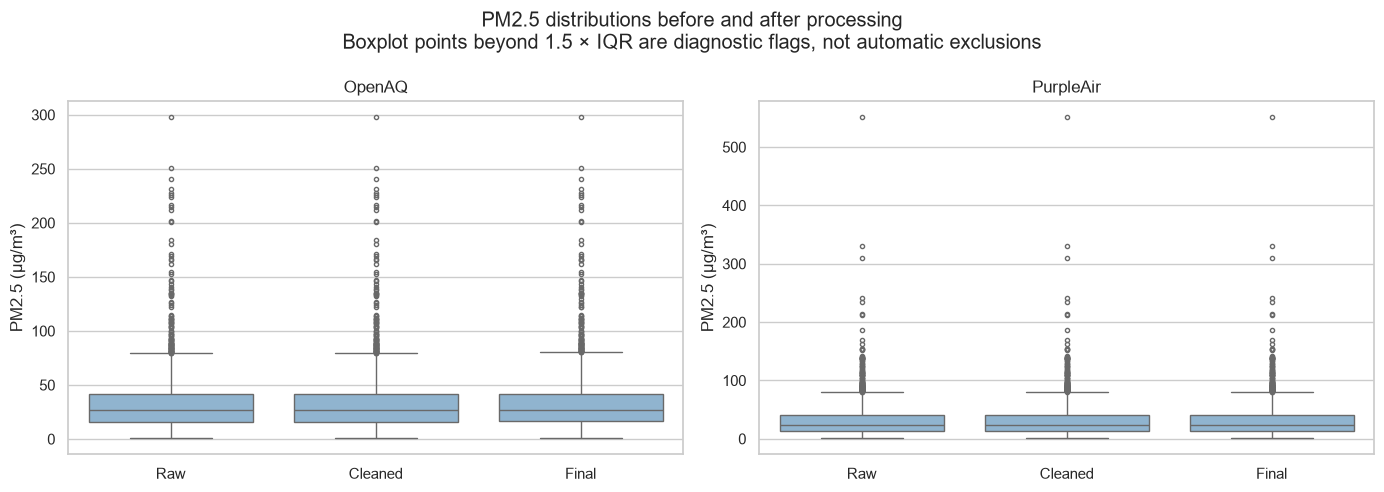

,rows
missing_channel,0
invalid_channel,0
channel_disagreement,1
rejected,1


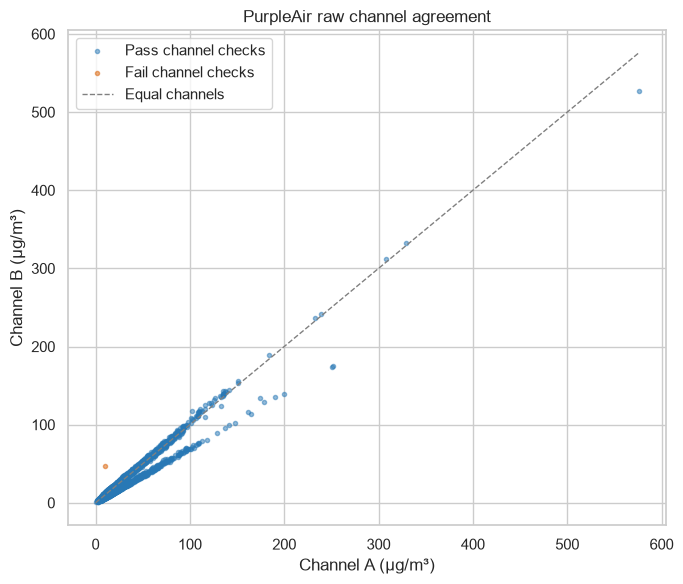

IQR outliers are retained unless they independently fail a cleaning rule.


observations  iqr_flags
stage source                            
Final OpenAQ             3387        139
      PurpleAir          2910        135
Raw   OpenAQ             3254        135
      PurpleAir          2906        134

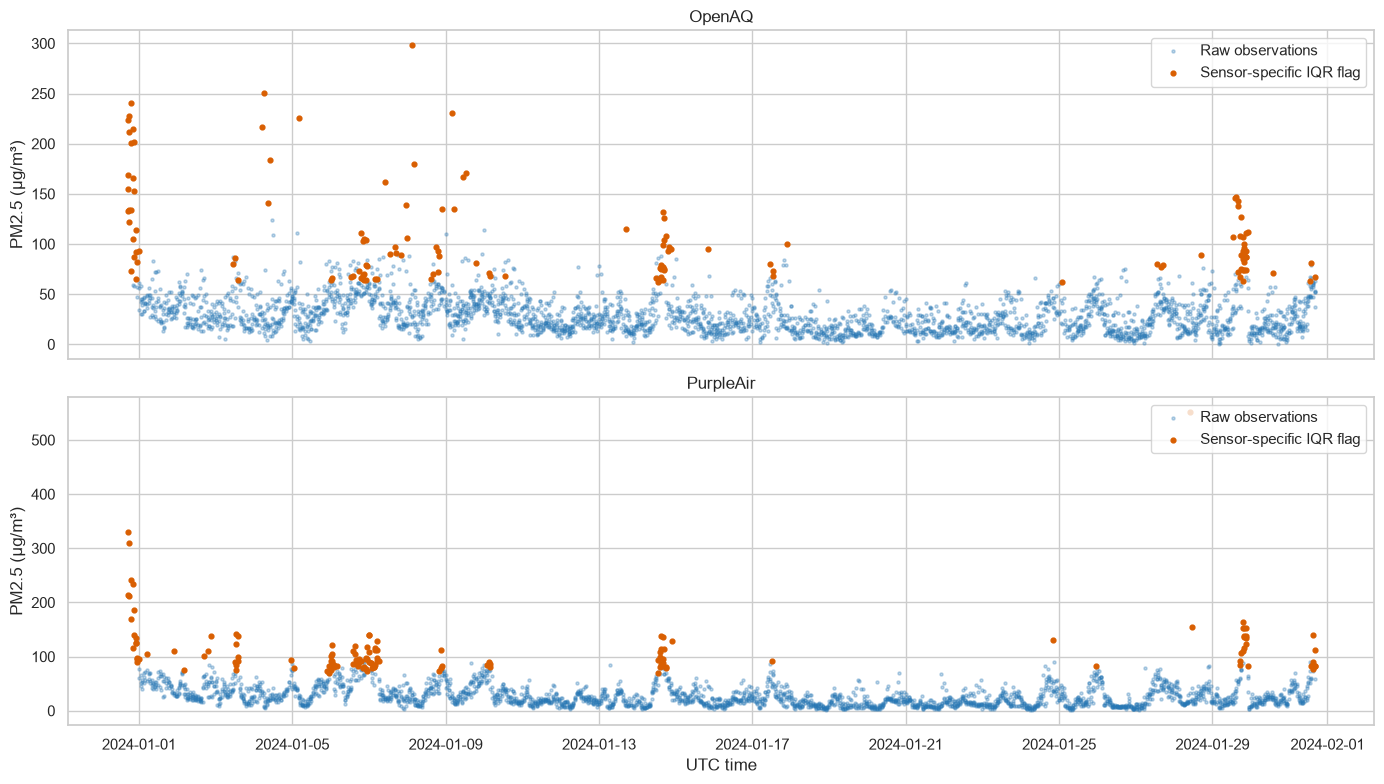

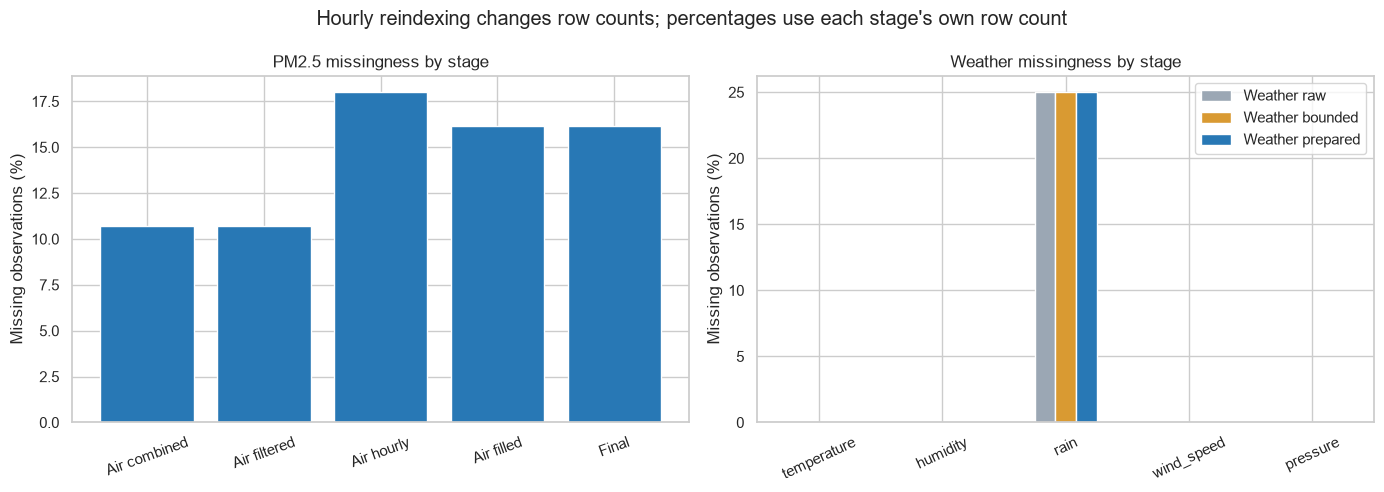

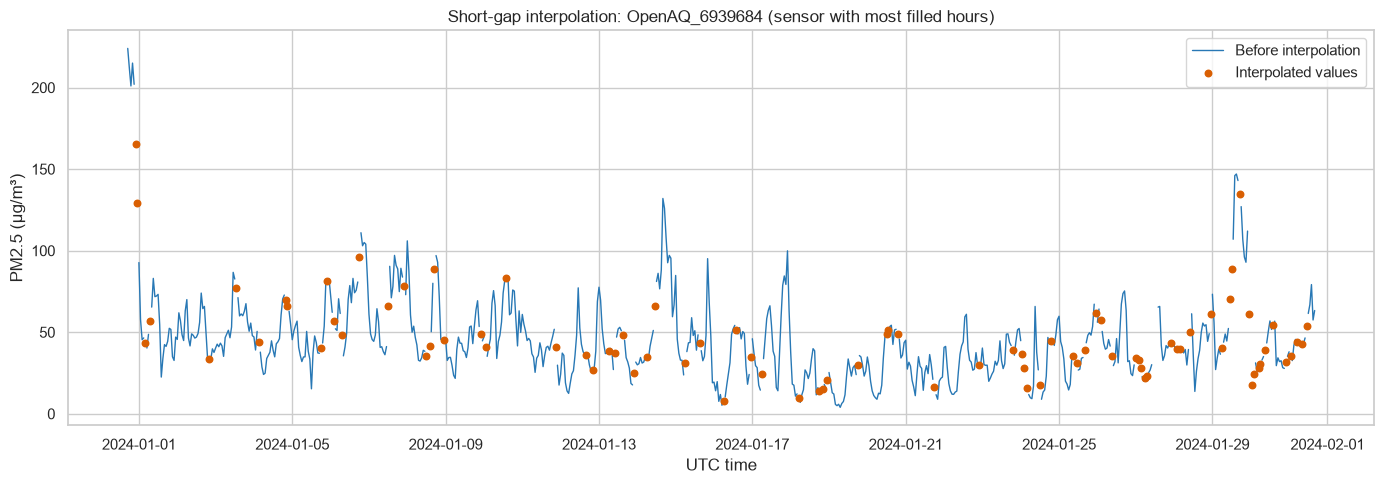

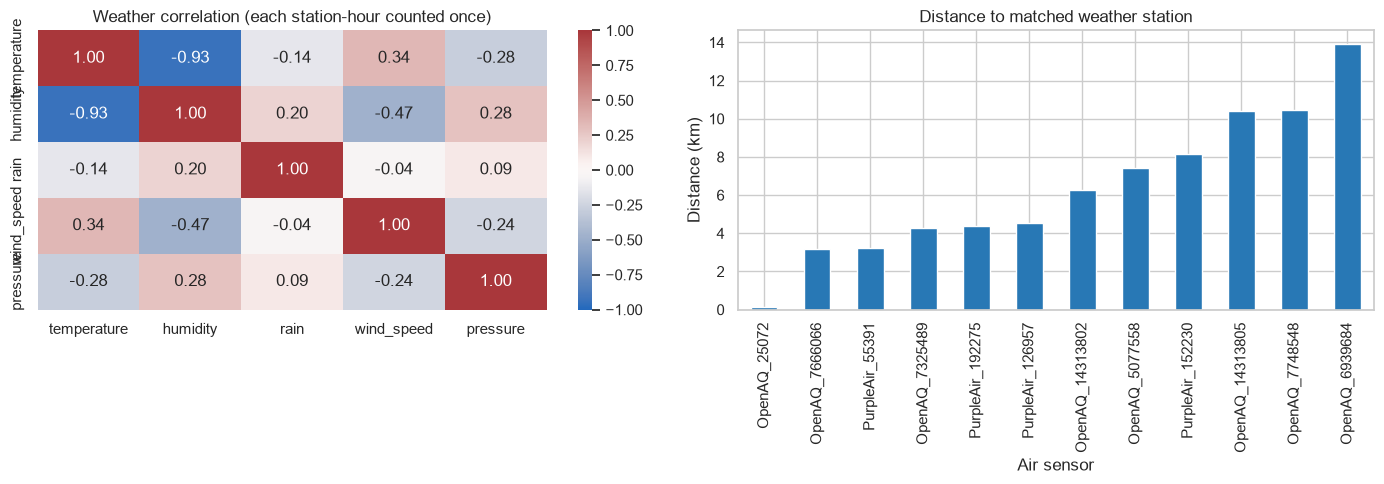

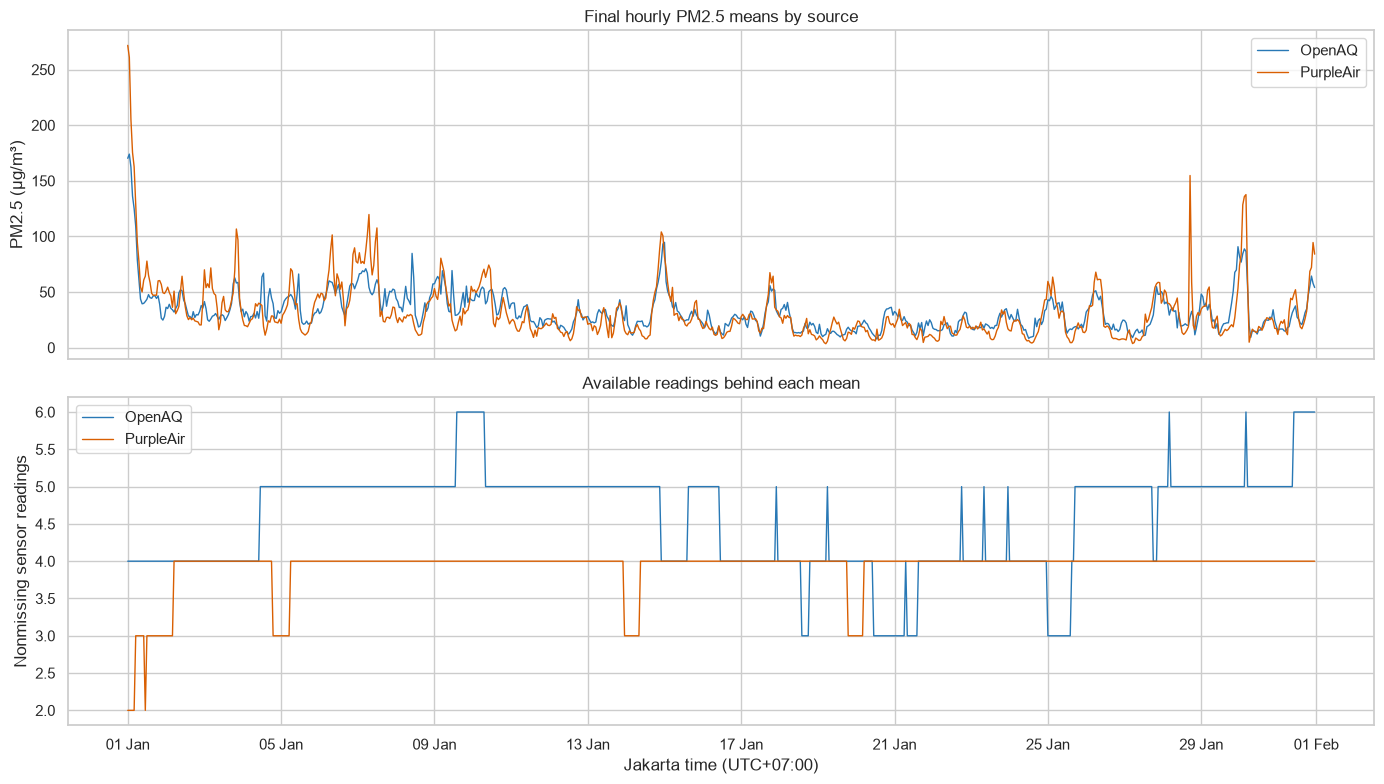

In [15]:
# Inspect cleaning effects and statistical outliers without modifying measurements.
raw_pm = openaq_raw.copy()
raw_pm["pm25"] = pd.to_numeric(raw_pm["pm25"], errors="coerce")
purple_plot = purpleair_raw.copy()
channels = ["pm2.5_cf_1_a", "pm2.5_cf_1_b"]
for column in channels:
    if column not in purple_plot:
        purple_plot[column] = np.nan
    purple_plot[column] = pd.to_numeric(purple_plot[column], errors="coerce")
# This mean is for raw diagnostics only. It is not a validated PM2.5 measurement.
purple_plot["pm25"] = purple_plot[channels].mean(axis=1, skipna=False)
purple_plot["source"] = "PurpleAir"
raw_pm = pd.concat([raw_pm, purple_plot], ignore_index=True)
raw_pm["time"] = pd.to_datetime(raw_pm["time"], utc=True, errors="coerce")

distribution = []
for label, frame in [("Raw", raw_pm), ("Cleaned", stage_data["Air combined"]), ("Final", analysis_ready)]:
    d = frame[["source", "pm25"]].copy()
    d["stage"] = label
    distribution.append(d)
distribution = pd.concat(distribution, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, source in zip(axes, ["OpenAQ", "PurpleAir"]):
    sns.boxplot(data=distribution.loc[distribution.source.eq(source)], x="stage", y="pm25", ax=ax,
                order=["Raw", "Cleaned", "Final"], color="#86b6d9", flierprops={"markersize": 3})
    ax.set(title=source, xlabel="", ylabel="PM2.5 (µg/m³)")
fig.suptitle("PM2.5 distributions before and after processing\nBoxplot points beyond 1.5 × IQR are diagnostic flags, not automatic exclusions")
save_graph(fig, "01_pm25_boxplots.png")

# Raw-channel rejection reasons; multiple flags can apply to one record.
channel_flags = purple_plot.copy()
channel_flags["missing_channel"] = channel_flags[channels].isna().any(axis=1)
channel_flags["invalid_channel"] = ((channel_flags[channels] < 0) | (channel_flags[channels] > 1000)).any(axis=1)
channel_flags["channel_disagreement"] = ((channel_flags[channels[0]] - channel_flags[channels[1]]).abs() > np.maximum(10, channel_flags.pm25 * 0.50))
channel_flags["rejected"] = channel_flags[["missing_channel", "invalid_channel", "channel_disagreement"]].any(axis=1)
display(channel_flags[["missing_channel", "invalid_channel", "channel_disagreement", "rejected"]].sum().to_frame("rows"))
fig, ax = plt.subplots(figsize=(7, 6))
for rejected, label, color in [(False, "Pass channel checks", "#2878b5"), (True, "Fail channel checks", "#d95f02")]:
    rows = channel_flags.loc[channel_flags.rejected.eq(rejected)]
    ax.scatter(rows[channels[0]], rows[channels[1]], s=9, alpha=.5, label=label, color=color)
vals = channel_flags[channels].to_numpy(dtype=float)
finite = vals[np.isfinite(vals)]
if len(finite):
    lo, hi = min(0, finite.min()), max(1, finite.max())
    ax.plot([lo, hi], [lo, hi], color="grey", linestyle="--", linewidth=1, label="Equal channels")
ax.set(title="PurpleAir raw channel agreement", xlabel="Channel A (µg/m³)", ylabel="Channel B (µg/m³)")
ax.legend()
save_graph(fig, "02_purpleair_channels.png")

# Statistical outliers: compute each sensor's raw IQR once, then reuse those bounds.
bounds, flagged = [], []
for site_id, group in raw_pm.groupby("site_id"):
    values = group.pm25.replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) < 4:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr == 0:
        continue
    bounds.append({"site_id": site_id, "q1": q1, "q3": q3, "lower": q1 - 1.5 * iqr, "upper": q3 + 1.5 * iqr})
outlier_bounds = pd.DataFrame(bounds, columns=["site_id", "q1", "q3", "lower", "upper"])
for label, frame in [("Raw", raw_pm), ("Final", analysis_ready)]:
    marked = frame.merge(outlier_bounds, on="site_id", how="left", validate="many_to_one")
    marked["iqr_outlier"] = marked.pm25.lt(marked.lower) | marked.pm25.gt(marked.upper)
    marked["stage"] = label
    flagged.append(marked)
outlier_diagnostics = pd.concat(flagged, ignore_index=True)
outlier_rows = outlier_diagnostics.loc[outlier_diagnostics.iqr_outlier].copy()
print("IQR outliers are retained unless they independently fail a cleaning rule.")
display(outlier_diagnostics.groupby(["stage", "source"]).agg(observations=("pm25", "count"), iqr_flags=("iqr_outlier", "sum")))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, source in zip(axes, ["OpenAQ", "PurpleAir"]):
    group = outlier_diagnostics.loc[outlier_diagnostics.source.eq(source) & outlier_diagnostics.stage.eq("Raw")].sort_values("time")
    ax.scatter(group.time, group.pm25, s=5, alpha=.3, color="#2878b5", label="Raw observations")
    unusual = group.loc[group.iqr_outlier]
    ax.scatter(unusual.time, unusual.pm25, s=12, color="#d95f02", label="Sensor-specific IQR flag")
    ax.set(title=source, ylabel="PM2.5 (µg/m³)")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("UTC time")
save_graph(fig, "03_raw_outliers_over_time.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
air_stages = ["Air combined", "Air filtered", "Air hourly", "Air filled", "Final"]
missing_pm = [stage_data[s].pm25.isna().mean() * 100 for s in air_stages]
axes[0].bar(air_stages, missing_pm, color="#2878b5")
axes[0].set(title="PM2.5 missingness by stage", ylabel="Missing observations (%)")
axes[0].tick_params(axis="x", rotation=20)
weather_missing = pd.DataFrame({s: stage_data[s][weather_columns].isna().mean() * 100 for s in ["Weather raw", "Weather bounded", "Weather prepared"]})
weather_missing.plot.bar(ax=axes[1], color=["#9ba7b4", "#d99a32", "#2878b5"])
axes[1].set(title="Weather missingness by stage", ylabel="Missing observations (%)", xlabel="")
axes[1].tick_params(axis="x", rotation=25)
fig.suptitle("Hourly reindexing changes row counts; percentages use each stage's own row count")
save_graph(fig, "04_missingness.png")

fig, ax = plt.subplots(figsize=(14, 5))
fill_counts = air_hourly.groupby("site_id").pm25_imputed.sum()
if fill_counts.max() > 0:
    selected_site = fill_counts.idxmax()
    original = air_hourly_before.loc[air_hourly_before.site_id.eq(selected_site)].sort_values("time")
    filled = air_hourly.loc[air_hourly.site_id.eq(selected_site)].sort_values("time")
    ax.plot(original.time, original.pm25, linewidth=1, color="#2878b5", label="Before interpolation")
    added = filled.loc[filled.pm25_imputed]
    ax.scatter(added.time, added.pm25, color="#d95f02", s=22, label="Interpolated values", zorder=3)
    ax.set_title(f"Short-gap interpolation: {selected_site} (sensor with most filled hours)")
    ax.legend()
else:
    ax.text(.5, .5, "No PM2.5 gaps were eligible for interpolation", ha="center", transform=ax.transAxes)
ax.set(xlabel="UTC time", ylabel="PM2.5 (µg/m³)")
save_graph(fig, "05_interpolation.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
matched_weather = integrated.drop_duplicates(["station_id", "time"])
sns.heatmap(matched_weather[weather_columns].corr(), vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("Weather correlation (each station-hour counted once)")
links.sort_values("distance_to_weather_km").plot.bar(x="site_id", y="distance_to_weather_km", ax=axes[1], legend=False, color="#2878b5")
axes[1].set(title="Distance to matched weather station", ylabel="Distance (km)", xlabel="Air sensor")
save_graph(fig, "06_weather_merge.png")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for source, color in [("OpenAQ", "#2878b5"), ("PurpleAir", "#d95f02")]:
    rows = analysis_ready.loc[analysis_ready.source.eq(source)]
    series = rows.groupby("time_jakarta").pm25.agg(["mean", "count"])
    axes[0].plot(series.index, series["mean"], label=source, color=color, linewidth=1)
    axes[1].plot(series.index, series["count"], label=source, color=color, linewidth=1)
axes[0].set(title="Final hourly PM2.5 means by source", ylabel="PM2.5 (µg/m³)")
axes[1].set(title="Available readings behind each mean", ylabel="Nonmissing sensor readings", xlabel="Jakarta time (UTC+07:00)")
from matplotlib.dates import DateFormatter
from zoneinfo import ZoneInfo
axes[1].xaxis.set_major_formatter(DateFormatter("%d %b", tz=ZoneInfo("Asia/Jakarta")))
for ax in axes:
    ax.legend()
save_graph(fig, "07_final_time_series.png")


## 8. Outlier removal and PCA dimensionality reduction

PCA uses standardized, complete numerical records from the explicitly licensed primary cohort. IQR filtering estimates typical-condition structure; a sensitivity comparison retains extremes. This is descriptive analysis, not a predictive train/test experiment.

,site_id,location,provider,licenses,explicit_open_license,source_url,downloaded_rows
2,OpenAQ_5077558,Jakarta South,AirNow,US Public Domain,True,https://api.openaq.org/v3/sensors/5077558/hours,740
3,OpenAQ_25072,Jakarta Central,AirNow,US Public Domain,True,https://api.openaq.org/v3/sensors/25072/hours,744
7,OpenAQ_6939684,Qoryah Darussalam,AirGradient,CC BY 4.0,True,https://api.openaq.org/v3/sensors/6939684/hours,655
8,OpenAQ_7325489,Jihan Fauziah Hamdi,AirGradient,CC BY 4.0,True,https://api.openaq.org/v3/sensors/7325489/hours,127
9,OpenAQ_7748548,Jakarta,Clarity,CC0 1.0,True,https://api.openaq.org/v3/sensors/7748548/hours,153
10,OpenAQ_7666066,Krukut,AirGradient,CC BY 4.0,True,https://api.openaq.org/v3/sensors/7666066/hours,162
15,OpenAQ_14313802,East Jakarta Mayor Office,Clean Air Catalyst,Not stated in response,False,https://api.openaq.org/v3/sensors/14313802/hours,705
16,OpenAQ_14313805,Rusunawa Marunda,Clean Air Catalyst,Not stated in response,False,https://api.openaq.org/v3/sensors/14313805/hours,704



Primary open data: OpenAQ sensors with explicit permissive license metadata, joined to Meteostat.
Rows: 7,511 -> 3,064; columns: 22 -> 22


,column,missing_before,missing_after
0,source,0,0
1,site_id,0,0
2,latitude,0,0
3,longitude,0,0
4,time,0,0
5,pm25,1214,1098
6,pm25_imputed,0,0
7,station_id,0,0
8,distance_to_weather_km,0,0
9,temperature,0,0


Changed cells / added or removed rows: 4,447


,stage,record,column,before,after,change
0,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 17:0...",(row),present,None,removed
1,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 18:0...",(row),present,None,removed
2,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 19:0...",(row),present,None,removed
3,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 20:0...",(row),present,None,removed
4,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 21:0...",(row),present,None,removed
5,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 22:0...",(row),present,None,removed
6,Primary open data,"('OpenAQ_14313802', Timestamp('2023-12-31 23:0...",(row),present,None,removed
7,Primary open data,"('OpenAQ_14313802', Timestamp('2024-01-01 00:0...",(row),present,None,removed
8,Primary open data,"('OpenAQ_14313802', Timestamp('2024-01-01 01:0...",(row),present,None,removed
9,Primary open data,"('OpenAQ_14313802', Timestamp('2024-01-01 02:0...",(row),present,None,removed


...

,stage,record,column,before,after,change
0,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 17:00:0...",(row),present,None,removed
1,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 18:00:0...",(row),present,None,removed
2,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 19:00:0...",(row),present,None,removed
3,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 20:00:0...",(row),present,None,removed
4,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 21:00:0...",(row),present,None,removed
5,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 22:00:0...",(row),present,None,removed
6,PCA complete cases,"('OpenAQ_25072', Timestamp('2023-12-31 23:00:0...",(row),present,None,removed
7,PCA complete cases,"('OpenAQ_25072', Timestamp('2024-01-01 00:00:0...",(row),present,None,removed
8,PCA complete cases,"('OpenAQ_25072', Timestamp('2024-01-01 01:00:0...",(row),present,None,removed
9,PCA complete cases,"('OpenAQ_25072', Timestamp('2024-01-01 02:00:0...",(row),present,None,removed


PCA: 1,169 rows; 6 standardized features -> 5 components; 99.28% variance retained.
IQR rows removed: 94; additional incomplete rows excluded: 1,801
Standardized reconstruction RMSE: 0.0851


,component,eigenvalue,variance_fraction,cumulative_fraction
0,PC1,2.285203,0.380867,0.380867
1,PC2,1.146836,0.191139,0.572007
2,PC3,0.995362,0.165894,0.737900
3,PC4,0.940873,0.156812,0.894712
4,PC5,0.588261,0.098044,0.992756
5,PC6,0.043465,0.007244,1.000000


component,feature,PC1,PC2,PC3,PC4,PC5,PC6
0,pm25,0.208932,0.701881,-0.180738,0.373515,0.539928,-0.002840
1,temperature,-0.580327,0.294482,0.330703,0.014474,-0.053978,0.681185
2,humidity,0.619787,-0.206064,-0.223509,-0.000285,-0.042783,0.722229
3,rain,0.161965,-0.246857,0.547747,0.775681,-0.095261,-0.045249
4,wind_speed,-0.352135,-0.562836,-0.236330,0.151709,0.684437,0.109068
5,pressure,0.291891,-0.021396,0.672410,-0.485366,0.475611,-0.020519


,cohort,rows,components_95pct,pc1_fraction
0,Complete cases without IQR removal,1225,5,0.377306
1,Complete cases after IQR removal,1169,5,0.380867


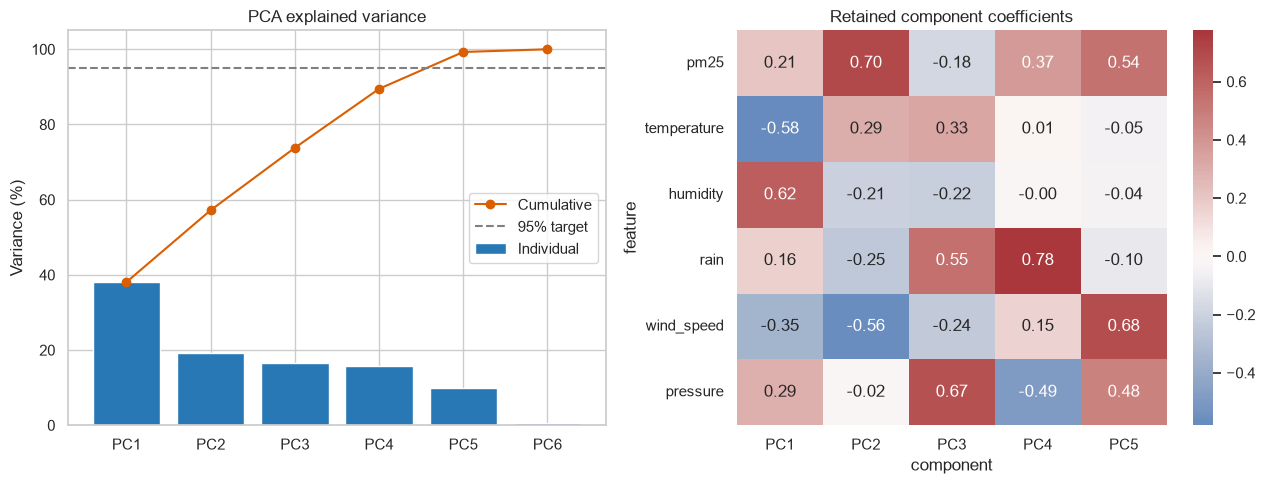

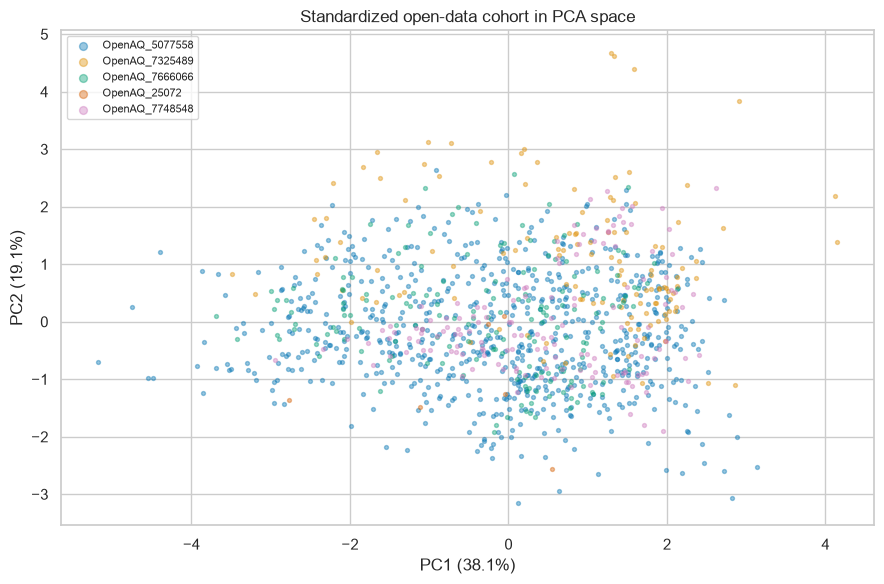

In [16]:
# Primary openly licensed cohort: outlier removal and standardized PCA.
permissive = {"US Public Domain", "CC0 1.0", "CC BY 4.0"}
locations = get_openaq_results("https://api.openaq.org/v3/locations", {"X-API-Key": OPENAQ_API_KEY},
                             {"bbox": f"{WEST},{SOUTH},{EAST},{NORTH}", "parameters_id": 2, "limit": 1000})
source_rows = []
for location in locations:
    for sensor in location.get("sensors", []):
        if sensor.get("parameter", {}).get("id") == 2:
            licenses = [lic.get("name", "") for lic in location.get("licenses") or []]
            source_rows.append({"site_id": f"OpenAQ_{sensor['id']}", "location": location.get("name"),
                                "provider": (location.get("provider") or {}).get("name"),
                                "licenses": "; ".join(licenses) or "Not stated in response",
                                "explicit_open_license": any(x in permissive for x in licenses),
                                "source_url": f"https://api.openaq.org/v3/sensors/{sensor['id']}/hours"})
source_catalog = pd.DataFrame(source_rows)
source_catalog["downloaded_rows"] = source_catalog.site_id.map(openaq_raw.site_id.value_counts()).fillna(0).astype(int)
display(source_catalog.loc[source_catalog.downloaded_rows.gt(0)])
open_ids = source_catalog.loc[source_catalog.explicit_open_license, "site_id"]
primary = analysis_ready.loc[analysis_ready.site_id.isin(open_ids)].copy()
snapshot("Primary open data", primary, "OpenAQ sensors with explicit permissive license metadata, joined to Meteostat.", "Final", ["site_id", "time"])

# Fixed raw sensor-specific IQR bounds from the diagnostics section are reused.
primary_flags = primary.merge(outlier_bounds, on="site_id", how="left", validate="many_to_one")
primary_flags["iqr_outlier"] = primary_flags.pm25.lt(primary_flags.lower) | primary_flags.pm25.gt(primary_flags.upper)
trimmed = primary_flags.loc[~primary_flags.iqr_outlier, primary.columns].copy()
snapshot("Outlier filtered", trimmed, "Sensor-specific 1.5 × IQR extremes removed for typical-condition PCA only; original high readings remain in Final.", "Primary open data", ["site_id", "time"])

candidate_features = [c for c in ["pm25", "temperature", "humidity", "rain", "wind_speed", "pressure"] if c in analysis_ready]
complete = trimmed.dropna(subset=candidate_features).copy()
snapshot("PCA complete cases", complete, "Only rows observed or short-gap-imputed in every selected numerical feature enter PCA.", "Outlier filtered", ["site_id", "time"])
features = [c for c in candidate_features if complete[c].std(ddof=1) > 0]
if len(complete) < 3 or len(features) < 2:
    raise ValueError("Insufficient complete, nonconstant features for PCA")

def fit_pca(frame, selected_features):
    x = frame[selected_features].to_numpy(dtype=float)
    mean, scale = x.mean(axis=0), x.std(axis=0, ddof=1)
    z = (x - mean) / scale
    u, singular, vt = np.linalg.svd(z, full_matrices=False)
    # Fix signs for reproducible loading orientation.
    for j in range(len(vt)):
        if vt[j, np.abs(vt[j]).argmax()] < 0:
            vt[j] *= -1
            u[:, j] *= -1
    eigenvalues = singular ** 2 / (len(x) - 1)
    ratios = eigenvalues / eigenvalues.sum()
    scores = z @ vt.T
    return z, mean, scale, vt, eigenvalues, ratios, scores

z, centers, scales, components, eigenvalues, ratios, scores = fit_pca(complete, features)
cumulative = np.cumsum(ratios)
k = int(np.searchsorted(cumulative, .95) + 1)
variance = pd.DataFrame({"component": [f"PC{i+1}" for i in range(len(ratios))],
                         "eigenvalue": eigenvalues, "variance_fraction": ratios, "cumulative_fraction": cumulative})
loadings = pd.DataFrame(components.T, index=features, columns=variance.component).reset_index(names="feature")
scaling = pd.DataFrame({"feature": features, "mean": centers, "sample_std": scales})
pca_scores = complete[["source", "site_id", "time"]].reset_index(drop=True)
for j in range(k): pca_scores[f"PC{j+1}"] = scores[:, j]
covariance = pd.DataFrame(np.cov(z, rowvar=False), index=features, columns=features).reset_index(names="feature")
reconstruction_rmse = float(np.sqrt(np.mean((z - scores[:, :k] @ components[:k]) ** 2)))
untrimmed_complete = primary.dropna(subset=features)
*_, full_ratios, _ = fit_pca(untrimmed_complete, features)
sensitivity = pd.DataFrame([
    {"cohort": "Complete cases without IQR removal", "rows": len(untrimmed_complete), "components_95pct": int(np.searchsorted(np.cumsum(full_ratios), .95) + 1), "pc1_fraction": full_ratios[0]},
    {"cohort": "Complete cases after IQR removal", "rows": len(complete), "components_95pct": k, "pc1_fraction": ratios[0]},
])
print(f"PCA: {len(complete):,} rows; {len(features)} standardized features -> {k} components; {cumulative[k-1]:.2%} variance retained.")
print(f"IQR rows removed: {primary_flags.iqr_outlier.sum():,}; additional incomplete rows excluded: {len(trimmed)-len(complete):,}")
print(f"Standardized reconstruction RMSE: {reconstruction_rmse:.4f}")
display(variance); display(loadings); display(sensitivity)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(variance.component, ratios * 100, color="#2878b5", label="Individual")
axes[0].plot(variance.component, cumulative * 100, marker="o", color="#d95f02", label="Cumulative")
axes[0].axhline(95, linestyle="--", color="grey", label="95% target")
axes[0].set(title="PCA explained variance", ylabel="Variance (%)", ylim=(0, 105)); axes[0].legend()
sns.heatmap(loadings.set_index("feature").iloc[:, :k], annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Retained component coefficients")
save_graph(fig, "08_pca_variance_loadings.png")
fig, ax = plt.subplots(figsize=(9, 6))
for site_id in pca_scores.site_id.unique():
    mask = pca_scores.site_id.eq(site_id)
    ax.scatter(scores[mask, 0], scores[mask, 1], s=8, alpha=.4, label=site_id)
ax.set(xlabel=f"PC1 ({ratios[0]:.1%})", ylabel=f"PC2 ({ratios[1]:.1%})", title="Standardized open-data cohort in PCA space")
ax.legend(fontsize=8, markerscale=2)
save_graph(fig, "09_pca_scores.png")

assert np.allclose(np.cov(z, rowvar=False).diagonal(), 1)
assert np.isclose(ratios.sum(), 1)
assert cumulative[k-1] >= .95
assert k == 1 or cumulative[k-2] < .95
assert not pca_scores.isna().any().any()


## 9. Export raw, intermediate and final data

In [17]:
# Export every stage, detailed changes, diagnostics, and native Excel charts.
stage_summary = pd.DataFrame(stage_info)
change_log = pd.DataFrame(changes, columns=["stage", "record", "column", "before", "after", "change"])
missing_summary = pd.DataFrame([
    {"stage": name, "column": col, "rows": len(frame), "missing": int(frame[col].isna().sum()),
     "missing_fraction": frame[col].isna().mean() if len(frame) else np.nan}
    for name, frame in stage_data.items() for col in frame.columns
])
numeric_summary = pd.concat([
    frame.select_dtypes(include="number").describe().T.reset_index(names="column").assign(stage=name)
    for name, frame in stage_data.items() if len(frame) and len(frame.select_dtypes(include="number").columns)
], ignore_index=True)
display(stage_summary)
display(change_log.groupby(["stage", "change"]).size().to_frame("entries"))

notes = pd.DataFrame([
    ["Period", f"{START_DATE} inclusive to {END_DATE} exclusive"],
    ["Workbook", "Frozen snapshots of this notebook run. Rerun the notebook to refresh all stages and graphs."],
    ["Raw data", "OpenAQ raw and PurpleAir raw preserve extracted measurements. Full API responses are in raw_responses. Weather downloaded preserves the Meteostat returned table."],
    ["Times", "Excel timestamps are numeric dates: time is UTC; time_jakarta is Jakarta local time. Raw JSON/CSV keeps timezone offsets."],
    ["Units", "PM2.5: µg/m³; temperature: °C; humidity: %; rain: mm per hour; wind_speed: km/h; pressure: hPa; distance: km."],
    ["Row changes", "Hourly resampling can add rows. Missing percentages are calculated using each stage's row count."],
    ["Changes", "Changes lists common-column value changes and rows added/removed on unique keys. Column additions/removals and aggregation are described in Stages."],
    ["Outliers", "Sensor-specific raw quartiles define 1.5 × IQR bounds, reused for final flags. At least 4 readings and nonzero IQR required. Flags preserve the Final archive; the separate primary PCA cohort excludes flagged IQR extremes."],
    ["PurpleAir", "Raw PM2.5 diagnostic mean requires both channels. Final values require both valid channels and agreement within max(10, 50% of mean). CF1 values are uncalibrated."],
    ["Comparability", "Sources have different sensors and coverage. Source means are descriptive and are not a calibrated citywide estimate."],
    ["Missing values", "Blank Excel cells represent missing values; zero remains zero. Rainfall and long gaps are not filled."],
    ["Stages", "Processing outputs are computed in Python; workbook charts read the exported summary cells."],
    ["PCA", "Primary cohort: explicitly licensed OpenAQ plus Meteostat. Remove sensor-specific IQR extremes, use complete cases, standardize by sample SD, and retain the smallest number of components reaching 95% variance."],
], columns=["topic", "explanation"])

tables = {"Stages": stage_summary, "Final": analysis_ready, "Changes": change_log,
          "Missingness": missing_summary, "Statistics": numeric_summary,
          "Outlier flags": outlier_rows, "IQR bounds": outlier_bounds,
          "Channel checks": channel_flags, **{k: v for k, v in stage_data.items() if k != "Final"},
          "Method": notes}

def export_table(name, frame):
    # CSV preserves the original timezone-bearing strings; Excel uses explicit wall-clock dates.
    frame.to_csv(OUTPUT_DIR / (name.replace(" ", "_") + ".csv"), index=False)
    values = frame.copy()
    date_cols = []
    for col in values.columns:
        if pd.api.types.is_datetime64_any_dtype(values[col]):
            date_cols.append(col)
            values[col] = values[col].map(lambda value: None if pd.isna(value) else value.isoformat())
    # Raw OpenAQ timestamps are returned as strings; give Excel sortable UTC dates.
    if "time" in values and "time" not in date_cols:
        parsed = pd.to_datetime(values["time"], utc=True, errors="coerce")
        if values["time"].notna().sum() == parsed.notna().sum():
            values["time"] = parsed.map(lambda value: None if pd.isna(value) else value.isoformat())
            date_cols.append("time")
    records = json.loads(values.to_json(orient="split", date_format="iso", double_precision=15, default_handler=str))
    return {"name": name, "columns": list(values.columns), "rows": records["data"], "date_columns": date_cols}

# Compact chart tables. These are snapshots of Python diagnostics from this run.
chart_rows = pd.DataFrame({"stage": ["Air combined", "Air filtered", "Air hourly", "Air filled", "Final"]})
chart_rows["rows"] = chart_rows.stage.map(lambda name: len(stage_data[name]))
chart_rows["missing_pm25"] = chart_rows.stage.map(lambda name: int(stage_data[name].pm25.isna().sum()))
daily = analysis_ready.assign(day=analysis_ready.time_jakarta.dt.strftime("%Y-%m-%d")).groupby(["day", "source"]).pm25.mean().unstack().reset_index()
bins = np.arange(0, 1001, 50)
histogram = pd.DataFrame({"PM2.5 bin (µg/m³)": [f"{a}–<{b}" if b < 1000 else f"{a}–{b}" for a, b in zip(bins[:-1], bins[1:])]})
for source in ["OpenAQ", "PurpleAir"]:
    histogram[source] = np.histogram(analysis_ready.loc[analysis_ready.source.eq(source), "pm25"].dropna(), bins=bins)[0]
tables.update({"Chart stages": chart_rows, "Chart daily": daily, "Chart distribution": histogram})

payload = {"tables": [export_table(name, frame) for name, frame in tables.items()],
           "output_dir": str(OUTPUT_DIR.resolve()), "graph_files": graph_files,
           "period": f"{START_DATE} to {END_DATE}"}
payload_file = OUTPUT_DIR / "workbook_data.json"
payload_file.write_text(json.dumps(payload, ensure_ascii=False, allow_nan=False), encoding="utf-8")
(RAW_DIR / "manifest.json").write_text(json.dumps(request_log, indent=2), encoding="utf-8")

# Streaming Python Excel export: keeps all snapshots without loading a million styled cells.
import xlsxwriter
from importlib.metadata import version
tables.update({"Source catalog": source_catalog, "PCA variance": variance, "PCA loadings": loadings,
               "PCA scaling": scaling, "PCA covariance": covariance, "PCA scores": pca_scores,
               "PCA sensitivity": sensitivity})
# Ensure the added PCA and primary-cohort tables also have CSV copies.
for name, frame in tables.items():
    frame.to_csv(OUTPUT_DIR / (name.replace(" ", "_") + ".csv"), index=False)

workbook_path = OUTPUT_DIR / "air_quality_audit.xlsx"
with xlsxwriter.Workbook(workbook_path, {"constant_memory": True, "strings_to_formulas": False, "strings_to_urls": False}) as book:
    header = book.add_format({"bold": True, "bg_color": "#233B5D", "font_color": "white", "text_wrap": True, "valign": "vcenter", "font_name": "Arial", "font_size": 10})
    body = book.add_format({"font_name": "Arial", "font_size": 10})
    number = book.add_format({"num_format": "0.00", "font_name": "Arial", "font_size": 10})
    date = book.add_format({"num_format": "yyyy-mm-dd hh:mm", "font_name": "Arial", "font_size": 10})
    percent = book.add_format({"num_format": "0.0%", "font_name": "Arial", "font_size": 10})
    title = book.add_format({"bold": True, "font_size": 16, "font_name": "Arial", "font_color": "#233B5D"})
    note_format = book.add_format({"text_wrap": True, "valign": "top", "font_name": "Arial", "font_size": 10})
    overview = book.add_worksheet("Overview")
    overview.hide_gridlines(2); overview.set_column(0, 0, 32); overview.set_column(1, 17, 12)
    overview.write(1, 0, "Jakarta air quality: preprocessing review", title)
    overview.write(2, 0, f"{START_DATE} inclusive to {END_DATE} exclusive")
    for row, (label, value) in enumerate([
        ("Final sensor-hours", len(analysis_ready)), ("Processing snapshots", len(stage_data)),
        ("PM2.5 hours imputed", int(air_hourly.pm25_imputed.sum())),
        ("Primary PCA rows", len(complete)), ("Components retained", k),
        ("Variance retained", float(cumulative[k-1]))], 4):
        overview.write(row, 0, label); overview.write(row, 1, value, percent if label == "Variance retained" else body)
    overview.write(11, 0, "Frozen run snapshots. Raw data are preserved; IQR removal applies only to the PCA cohort.")
    for name, frame in tables.items():
        sheet = book.add_worksheet(name)
        sheet.hide_gridlines(2); sheet.freeze_panes(1, 0)
        sheet.set_row(0, 34); sheet.set_column(0, max(0, len(frame.columns)-1), 19, body)
        for col, label in enumerate(frame.columns):
            sheet.write(0, col, str(label), header)
            if label in ["time", "time_jakarta"]: sheet.set_column(col, col, 23, date)
            if label in ["record", "source_url"]: sheet.set_column(col, col, 65)
            if label in ["note", "explanation"]: sheet.set_column(col, col, 105, note_format)
        for row_index, row in enumerate(frame.itertuples(index=False, name=None), 1):
            if name in ["Method", "Stages"]: sheet.set_row(row_index, 44)
            for col, value in enumerate(row):
                if value is None or (not isinstance(value, (list, dict)) and pd.isna(value)): continue
                label = str(frame.columns[col])
                if isinstance(value, (pd.Timestamp, datetime)):
                    stamp = pd.Timestamp(value)
                    if stamp.tzinfo is not None: stamp = stamp.tz_localize(None)
                    sheet.write_datetime(row_index, col, stamp.to_pydatetime(), date)
                elif isinstance(value, (bool, np.bool_)): sheet.write_boolean(row_index, col, bool(value))
                elif isinstance(value, (int, np.integer)): sheet.write_number(row_index, col, int(value))
                elif isinstance(value, (float, np.floating)):
                    if np.isfinite(value): sheet.write_number(row_index, col, float(value), percent if "fraction" in label else number)
                else: sheet.write_string(row_index, col, str(value))
        if len(frame.columns): sheet.autofilter(0, 0, len(frame), len(frame.columns)-1)

    def excel_chart(sheet_name, chart_type, chart_title, position, y_label):
        frame = tables[sheet_name]
        chart = book.add_chart({"type": chart_type})
        for col in range(1, len(frame.columns)):
            chart.add_series({"name": [sheet_name, 0, col], "categories": [sheet_name, 1, 0, len(frame), 0],
                              "values": [sheet_name, 1, col, len(frame), col]})
        chart.set_title({"name": chart_title}); chart.set_y_axis({"name": y_label})
        chart.set_legend({"position": "bottom"}); chart.set_size({"width": 670, "height": 340})
        overview.insert_chart(position, chart)
    excel_chart("Chart stages", "column", "Rows and missing PM2.5 by stage", "A15", "Rows")
    excel_chart("Chart daily", "line", "Daily means by source", "I15", "PM2.5 (µg/m³)")
    excel_chart("Chart distribution", "column", "Final PM2.5 distribution", "A33", "Readings")
    # Native editable PCA chart includes variance fractions, not eigenvalues.
    chart = book.add_chart({"type": "line"})
    for col in [2, 3]:
        chart.add_series({"name": ["PCA variance", 0, col], "categories": ["PCA variance", 1, 0, len(variance), 0], "values": ["PCA variance", 1, col, len(variance), col]})
    chart.set_title({"name": "PCA explained variance"}); chart.set_y_axis({"num_format": "0%"})
    chart.set_size({"width": 670, "height": 340}); overview.insert_chart("I33", chart)
    gallery = book.add_worksheet("Diagnostic figures")
    gallery.hide_gridlines(2)
    for i, file in enumerate(graph_files):
        gallery.insert_image(i * 38, 0, file, {"x_scale": .45, "y_scale": .45})

source_means = analysis_ready.groupby("source").pm25.agg(["count", "mean", "median", "max"])
metrics = {
    "raw_openaq": len(openaq_raw), "raw_purpleair": len(purpleair_raw), "final_rows": len(analysis_ready),
    "final_columns": len(analysis_ready.columns), "hourly_added": len(air_hourly)-len(air_data),
    "imputed_pm25": int(air_hourly.pm25_imputed.sum()), "missing_pm25": int(analysis_ready.pm25.isna().sum()),
    "missing_rain": int(analysis_ready.rain.isna().sum()), "source_summary": json.loads(source_means.to_json(orient="index")),
    "rejected_purpleair": int(channel_flags.rejected.sum()), "primary_rows": len(primary),
    "primary_sites": int(primary.site_id.nunique()), "iqr_removed": int(primary_flags.iqr_outlier.sum()),
    "pca_rows": len(complete), "pca_excluded_missing": len(trimmed)-len(complete), "features": features, "pca_k": k,
    "variance": ratios.tolist(), "cumulative": cumulative.tolist(), "rmse": reconstruction_rmse,
    "loadings": loadings.to_dict(orient="records"), "sensitivity": sensitivity.to_dict(orient="records"),
    "weather_corr": matched_weather[weather_columns].corr().to_dict(),
    "distance_min": float(links.distance_to_weather_km.min()), "distance_max": float(links.distance_to_weather_km.max()),
    "dropped_correlated": drop_columns, "graph_files": graph_files, "output_dir": str(OUTPUT_DIR.resolve()),
    "packages": {name: version(name) for name in ["pandas", "numpy", "meteostat", "matplotlib", "seaborn", "xlsxwriter"]},
}
(OUTPUT_DIR / "report_metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
analysis_ready.to_csv("airQuality_clean.csv", index=False)
assert len(analysis_ready) == len(stage_data["Merged"])
assert not analysis_ready.duplicated(["source", "site_id", "time"]).any()
print("Workbook:", workbook_path.resolve())
print("Graphs:", GRAPH_DIR.resolve())
print("PCA and report metrics saved. All validation checks passed.")


,stage,previous,rows,columns,missing_cells,exact_duplicate_rows,rows_delta,added_columns,removed_columns,note
0,OpenAQ raw,,3990,6,736,0,NaN,,,Downloaded PM2.5 values before cleaning; full ...
1,PurpleAir raw,,2906,8,0,0,NaN,,,Downloaded channel values before cleaning; ful...
2,Weather downloaded,,2980,13,9970,0,NaN,,,Meteostat returned values before column renami...
3,Stations downloaded,,5,9,0,0,NaN,,,Original Meteostat station metadata.
4,Weather raw,,2976,13,9957,0,NaN,,,Names standardized and requested date interval...
5,Weather bounded,Weather raw,2976,13,9957,0,0.0,,,Measurements outside the existing physical lim...
6,Weather prepared,Weather bounded,2976,18,9957,0,0.0,"humidity_imputed, pressure_imputed, rain_imput...",,Hourly grid; bounded gaps of at most 3 hours f...
7,PurpleAir mean,PurpleAir raw,2906,9,0,0,0.0,pm25,,Unvalidated mean derived from both raw channel...
8,OpenAQ cleaned,OpenAQ raw,3990,6,736,0,0.0,,,Exact duplicates removed; timestamp/numeric ty...
9,PurpleAir cleaned,PurpleAir mean,2906,6,1,0,0.0,,"pm2.5_cf_1_a, pm2.5_cf_1_b, time_stamp",Exact duplicates removed; both channels must b...


,,entries
stage,change,
Air filled,filled,138
Air hourly,added,615
Outlier filtered,removed,94
PCA complete cases,removed,1801
Primary open data,removed,4447
PurpleAir cleaned,invalidated,1


Workbook: D:\Coding\RekayasaData\outputs\air-quality-review\20260927T122914815024Z\air_quality_audit.xlsx
Graphs: D:\Coding\RekayasaData\outputs\air-quality-review\20260927T122914815024Z\graphs
PCA and report metrics saved. All validation checks passed.


## 10. Findings and assignment coverage

- **Cleaning:** one PurpleAir channel pair is rejected. Hourly resampling exposes 615 missing sensor-hours; 138 short gaps are interpolated. Final PM2.5 missingness is 1,214 / 7,511 = **16.16%**. All original responses and extracted values are preserved.
- **Integration:** the final table has **7,511 rows and 22 columns**, with validated station/time joins. Matched weather stations are 0.13–13.93 km away. Temperature and humidity correlate at **−0.931**; no weather pair exceeds the declared absolute 0.95 redundancy cutoff.
- **Outlier removal:** the primary open-data branch excludes **94 IQR extremes**. It does not erase these values from the main audit table. This branch emphasizes typical conditions and may underrepresent true pollution episodes.
- **PCA:** after excluding incomplete feature vectors, **1,169 rows** enter PCA. Six standardized features require **five components for 99.28% variance**; four explain only 89.47%. The sensitivity run without IQR removal also requires five components.
- **Coverage limitation:** complete cases retain five primary sensors, with 717 rows from one sensor. The source averages and PCA patterns describe this selected sample, not the entire city or a causal weather–pollution relationship.
- **Deliverables:** the notebook contains all Python code, executed results, nine figures and source links. The six-page PDF companion and standalone LaTeX source summarize the project. The presentation is excluded as requested.

**Before submission:** confirm dataset uniqueness with the class register/instructor. Keep the `data/air_quality_snapshot` folder beside the notebook for credential-free reproduction. The original deadline is in 2025; the source collection and document generation dates have not been backdated.
